# SHIELD Phase 0 diagnostics (Colab)
*New file, not from the starter code (byzantine_skew / STRIKE).*

Runs the starter code with the STRIKE (`skew`) attack and logs the Phase 0 diagnostics each round:
distance contrast, variance spectrum, and out-of-subspace residuals for benign vs Byzantine updates.

**Before running:** Runtime > Change runtime type > **T4 GPU**.

## 1. Check the GPU

In [1]:
# * confirm a GPU is attached (the starter code calls .cuda() directly)
!nvidia-smi
import torch
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'

Sun Nov 22 14:59:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Get the code
Set `REPO_URL` to your own GitHub repo (private repos need a token in the URL), **or** leave it empty and upload a zip of the `SHIELD` folder (exclude `.venv` and `.git`).

In [2]:
# * option A: clone from GitHub. option B: leave REPO_URL empty and upload a zip
REPO_URL = 'https://github.com/edominicduke/SHIELD.git'   # e.g. 'https://github.com/<you>/<repo>.git'
import os, shutil, zipfile
%cd /content
shutil.rmtree('/content/SHIELD', ignore_errors=True)
if REPO_URL:
    !git clone {REPO_URL} SHIELD
else:
    from google.colab import files
    up = files.upload()                     # * pick the zip of the SHIELD folder
    name = next(iter(up))
    os.makedirs('/content/SHIELD', exist_ok=True)
    with zipfile.ZipFile(name) as z:
        z.extractall('/content/SHIELD')
    # * if the zip contained a single top-level folder, step into it
    entries = os.listdir('/content/SHIELD')
    if 'main.py' not in entries and len(entries) == 1:
        inner = os.path.join('/content/SHIELD', entries[0])
        for e in os.listdir(inner):
            shutil.move(os.path.join(inner, e), '/content/SHIELD')
%cd /content/SHIELD
assert os.path.exists('main.py'), 'main.py not found; check the upload'
!ls

/content
Cloning into 'SHIELD'...
remote: Enumerating objects: 117, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 117 (delta 60), reused 111 (delta 56), pack-reused 0 (from 0)
Receiving objects: 100% (117/117), 46.32 KiB | 2.57 MiB/s, done.
Resolving deltas: 100% (60/60), done.
/content/SHIELD
configs  fl  main.py  phase0_colab.ipynb  requirements.txt


## 3. Install dependencies
Colab already ships torch/torchvision/numpy; only wandb is needed (and only if you pass `--wandb`).

In [3]:
# * wandb is imported lazily by the code, so this is optional; installed for completeness
!pip -q install wandb

## 4. Run
Defaults: CIFAR-10, AlexNet, 50 clients, 20% Byzantine, `mean` aggregator (so the defense does not alter benign updates), STRIKE attack. `--nice` skips the GPU-memory-hogging `block()` helper. `ROUNDS` is kept small for a first pass; the paper config uses 200.

In [4]:
# * experiment settings (edit these)
DATASET, ROUNDS, BYZ_RATIO, ATTACK, AGG, SEED = 'cifar10', 30, 0.2, 'skew', 'mean', 0
PARTITION = 'dirichlet'
EXTRA = ''                 # * e.g. '--ben_known_ratio 0.5'
LOG = '/content/phase0.log'
cmd = (f'python main.py --dataset {DATASET} --framework fedavg --aggregator {AGG} --attack {ATTACK} '
       f'--byz_client_ratio {BYZ_RATIO} --partition {PARTITION} --server_n_epochs {ROUNDS} '
       f'--seed {SEED} --devices 0 --nice --phase0_diag {EXTRA}')
print(cmd)
!{cmd} 2>&1 | tee {LOG} | grep -E "epoch|te_acc|p0_ben_dist_contrast|p0_byz_nn_dist_ratio|p0_res_(ben|byz)_frac_k5"

python main.py --dataset cifar10 --framework fedavg --aggregator mean --attack skew --byz_client_ratio 0.2 --partition dirichlet --server_n_epochs 30 --seed 0 --devices 0 --nice --phase0_diag 
args: Namespace(dataset='cifar10', data_root='data/cifar10', n_classes=10, n_clients=50, partition='dirichlet', dirichlet_beta=0.5, dirichlet_min_n_data=10, byz_client_ratio=0.2, ben_known_ratio=0, attack='skew', ipm_epsilon=0.1, lie_z=1.5, minmax_deviation='std', minsum_deviation='std', omn_deviation='std', omn_evals=8, skew_lambda=1, architecture='alexnet', loss='cross_entropy', framework='fedavg', server_n_epochs=30, n_sampled_clients=50, client_sample_ratio=1.0, nnm=False, bucket_s=1, aggregator='mean', cc_l=1, cc_tau=10, dnc_n_iters=1, dnc_b=1000, dnc_c=1.0, rfa_budget=8, rfa_eps=1e-07, client_batch_size=128, client_optimizer='sgd', client_lr=0.1, client_momentum=0.9, client_weight_decay=0.0001, client_n_epochs=1, clip_max_norm=2.0, seed=0, pin_memory=False, n_workers=1, te_batch_size=128, p

## 5. Parse the log into per-round diagnostics

In [8]:
# * rebuild per-round dicts from the printed 'SHIELD phase0 diagnostics' and 'performance' blocks
import ast, re
import pandas as pd

rows, cur, section = [], None, None
for line in open(LOG, errors='ignore'):
    line = line.rstrip('\n')
    m = re.match(r'=+ epoch (\d+) time', line)
    if m:
        cur = {'round': int(m.group(1))}; rows.append(cur); section = None; continue
    h = re.match(r'=+ (.+?) =+$', line)
    if h:
        section = h.group(1); continue
    if cur is not None and section and (section.startswith('SHIELD phase0') or section.startswith('performance')):
        if ': ' in line:
            k, v = line.split(': ', 1)
            if k.startswith('p0_') or k in ('te_acc', 'best_te_acc'):
                try: cur[k] = ast.literal_eval(v)
                except Exception: pass
df = pd.DataFrame(rows)
print(df.shape); df.filter(regex='round|te_acc|contrast|nn_dist|byz_max').tail()

(30, 29)


,round,te_acc,best_te_acc,p0_ben_dist_contrast,p0_byz_nn_dist_ratio,p0_byz_max_pairwise_dist
25,25,32.92,32.92,4.344337,1.047227,0.0
26,26,29.40,32.92,4.517134,1.786954,0.0
27,27,32.75,32.92,4.431159,1.211940,0.0
28,28,31.26,32.92,4.355484,1.553133,0.0
29,29,32.97,32.97,4.465720,1.542492,0.0


## 6. Plots
The key question: **is the Byzantine residual fraction (orange) separated from the benign one (blue) at some k?**
Remember benign residuals are in-sample and biased low, and reach 0 at k = n_benign - 1.

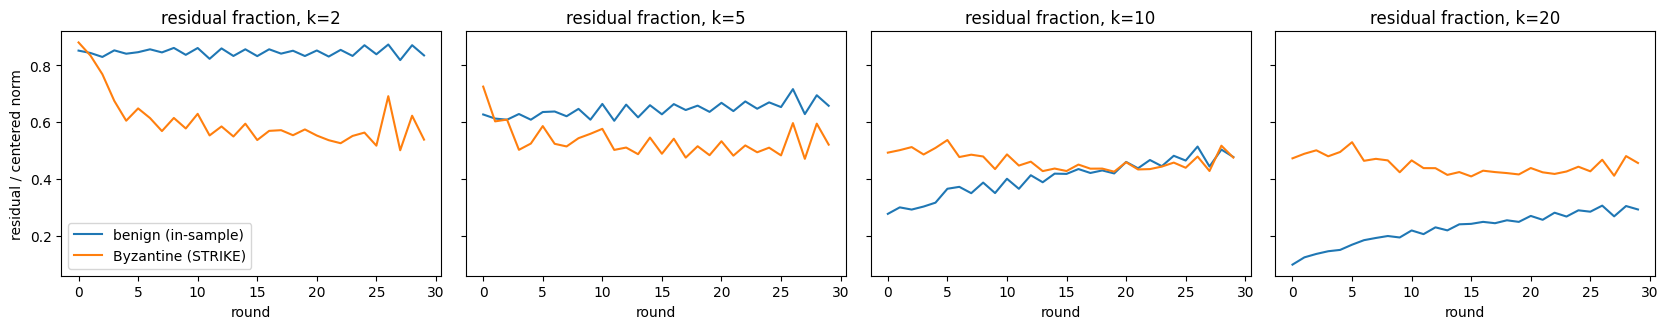

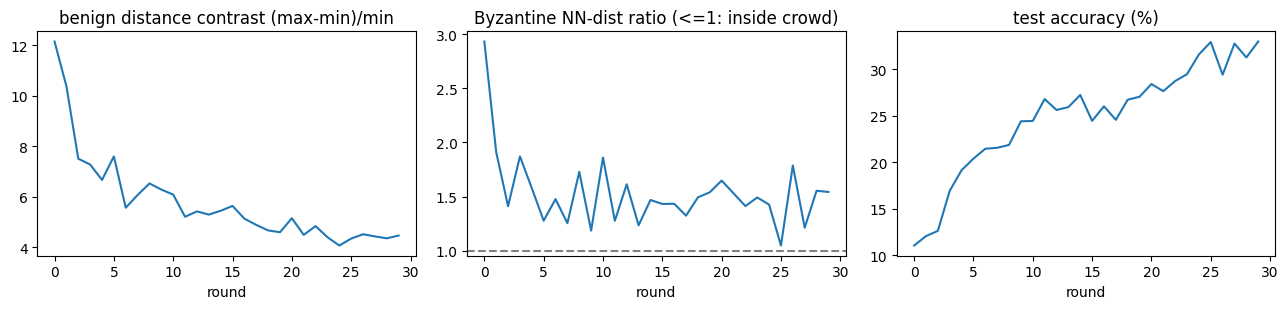

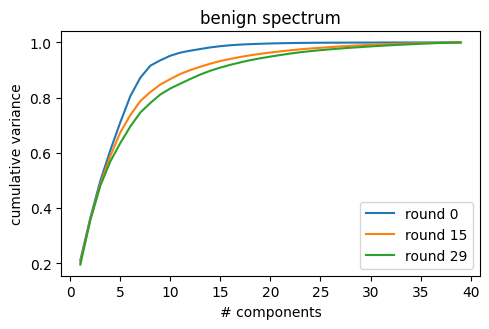

In [9]:
import matplotlib.pyplot as plt
ks = [k for k in (2, 5, 10, 20) if f'p0_res_byz_frac_k{k}' in df]
fig, axes = plt.subplots(1, len(ks), figsize=(4.2*len(ks), 3.4), sharey=True)
axes = [axes] if len(ks) == 1 else axes
for ax, k in zip(axes, ks):
    ax.plot(df['round'], df[f'p0_res_ben_frac_k{k}'], label='benign (in-sample)')
    ax.plot(df['round'], df[f'p0_res_byz_frac_k{k}'], label='Byzantine (STRIKE)')
    ax.set_title(f'residual fraction, k={k}'); ax.set_xlabel('round')
axes[0].set_ylabel('residual / centered norm'); axes[0].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(df['round'], df['p0_ben_dist_contrast']); ax[0].set_title('benign distance contrast (max-min)/min')
ax[1].plot(df['round'], df['p0_byz_nn_dist_ratio']); ax[1].axhline(1, ls='--', c='gray')
ax[1].set_title('Byzantine NN-dist ratio (<=1: inside crowd)')
ax[2].plot(df['round'], df['te_acc']); ax[2].set_title('test accuracy (%)')
for a in ax: a.set_xlabel('round')
plt.tight_layout(); plt.show()

# * cumulative variance spectrum at a few rounds (how many dims carry the benign variance)
fig, ax = plt.subplots(figsize=(5, 3.4))
for r in sorted(set([0, len(df)//2, len(df)-1])):
    cv = df.loc[r, 'p0_var_cumulative']
    ax.plot(range(1, len(cv)+1), cv, label=f'round {df.loc[r, "round"]}')
ax.set_xlabel('# components'); ax.set_ylabel('cumulative variance'); ax.legend(); ax.set_title('benign spectrum')
plt.tight_layout(); plt.show()

## 7. Summary table and verdict helper

In [10]:
# * mean over rounds; a ratio well above 1 at some k suggests a usable detector signal
summ = []
for k in ks:
    b, z = df[f'p0_res_ben_frac_k{k}'].mean(), df[f'p0_res_byz_frac_k{k}'].mean()
    summ.append({'k': k, 'benign_frac': b, 'byz_frac': z, 'byz/benign': z / (b + 1e-12)})
display(pd.DataFrame(summ))
print('mean benign distance contrast:', df['p0_ben_dist_contrast'].mean())
print('mean Byzantine NN-dist ratio :', df['p0_byz_nn_dist_ratio'].mean())
print('Byzantine updates identical  :', bool((df['p0_byz_max_pairwise_dist'] < 1e-6).all()))
df.to_csv('/content/phase0_results.csv', index=False)   # * download from the Files pane to keep

,k,benign_frac,byz_frac,byz/benign
0,2,0.845603,0.602732,0.712784
1,5,0.643097,0.533189,0.829095
2,10,0.403084,0.463105,1.148904
3,20,0.224657,0.447856,1.993507


mean benign distance contrast: 5.782707484563192
mean Byzantine NN-dist ratio : 1.531313451131185
Byzantine updates identical  : True
